# 🧪 Virtual Screening with CADD

Welcome, CADDers!  
In this notebook, we will explore how to perform **virtual screening** using multiple drug-likeness and lead optimization criteria. The goal is to filter and prioritize compounds with favorable pharmacokinetic and chemical properties for drug development.

## 🔍 Screening Criteria

We will evaluate compounds using the following key filters:

- **Lipinski's Rule of Five** — To assess oral bioavailability.
- **Quantitative Estimate of Drug-Likeness (QED)** — A score that combines multiple properties into a single drug-likeness metric.
- **Synthetic Accessibility Score (SAscore)** — To estimate the ease of chemical synthesis.
- **PAINS (Pan Assay Interference Compounds)** — To flag problematic substructures that may lead to false positives in screening assays.
- **Tanimoto Similarity** — To measure molecular similarity (e.g., with known active compounds) based on fingerprints.

Let's begin by preparing the necessary tools and datasets.

Assignment 
1. ROV = 0
2. QED = >= 0.67
3. SAScore = <=4
4. PAINS
5. Tanimoto: ref Smiles = "C1=CC2=C(C=CC(=C2))N=C1", 0.3


In [1]:
import pandas as pd
import rdkit 
from rdkit import Chem

In [2]:
df = pd.read_csv("chembl_22_clean_1576904_sorted_std_final.smi", sep="\t", header=None, names=["smiles", "name"])

In [3]:
df

,smiles,name
0,CCO,CHEMBL545
1,C,CHEMBL17564
2,CO,CHEMBL14688
3,NCCS,CHEMBL602
4,NCCN,CHEMBL816
...,...,...
1576899,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077161
1576900,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077162
1576901,n1(cnc2c1N=C(N)NC2=O)C1OC(COP(O)(=O)OC2C(COP(O...,CHEMBL1077165
1576902,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077164


In [4]:
df.isna().sum()

smiles    0
name      0
dtype: int64

## 💊 Lipinski's Rule of Five

Lipinski's Rule of Five is a widely used guideline in drug discovery to evaluate the **oral bioavailability** of a compound. It helps identify molecules that are more likely to become orally active drugs in humans.

A compound is considered likely to have good oral bioavailability if **no more than one** of the following rules is violated:

- 🔹 **Molecular weight** ≤ 500 Da  
- 🔹 **LogP** (octanol-water partition coefficient) ≤ 5  
- 🔹 **Hydrogen bond donors** (OH and NH groups) ≤ 5  
- 🔹 **Hydrogen bond acceptors** (N and O atoms) ≤ 10  

These rules are not absolute but serve as a **filter to prioritize drug-like molecules** during virtual screening.

> 📌 Note: Compounds that violate multiple rules may still be biologically active but are less likely to be orally bioavailable.



In [5]:
df

,smiles,name
0,CCO,CHEMBL545
1,C,CHEMBL17564
2,CO,CHEMBL14688
3,NCCS,CHEMBL602
4,NCCN,CHEMBL816
...,...,...
1576899,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077161
1576900,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077162
1576901,n1(cnc2c1N=C(N)NC2=O)C1OC(COP(O)(=O)OC2C(COP(O...,CHEMBL1077165
1576902,CC1=CN(C2CC(OP(O)(=O)OCC3OC(C(O)C3OP(O)(=O)OCC...,CHEMBL1077164


In [6]:
df= df.sample(500_000, random_state=10)

In [7]:
df

,smiles,name
1451325,CC(C)C1NC(=O)C(Cc2ccccc2)NC(=O)C(CC(O)=O)NC(=O...,CHEMBL3357753
1350072,Cc1cc(cc2[nH]c(nc12)C1=C(NCC(O)c2cccc(Cl)c2)C=...,CHEMBL520419
1034729,O=C(NN1CCN(CCc2c[nH]c3ccccc23)CC1)c1ccc(cc1)N(...,CHEMBL3273067
346860,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177
852483,COc1ccccc1NC(=O)CSc1ccc(nn1)-c1ccc(cc1)-n1ccnc1,CHEMBL1442008
...,...,...
859693,Clc1ccc2C(N3CCN(CC3)C(=O)C3CCNCC3)c3ncccc3CCc2c1,CHEMBL352634
1401187,Cc1nc(sc1C(Cc1ccc(F)cc1F)Sc1ccc(OCC(O)=O)c(C)c...,CHEMBL2035060
1194408,COC(=O)C(CC(C)=O)CS(=O)(=O)C=C(O)C(=O)Nc1cccc(...,CHEMBL2004630
249270,COc1cc(C=CC(=O)c2cc(O)ccc2O)ccc1O,CHEMBL3335598


In [8]:
df['Mol'] = df['smiles'].apply(Chem.MolFromSmiles)

[16:20:18] Explicit valence for atom # 27 O, 2, is greater than permitted
[16:20:18] Explicit valence for atom # 16 O, 2, is greater than permitted
[16:20:19] Explicit valence for atom # 22 O, 2, is greater than permitted
[16:20:19] Explicit valence for atom # 36 O, 2, is greater than permitted
[16:20:20] Explicit valence for atom # 27 O, 2, is greater than permitted
[16:20:20] Explicit valence for atom # 26 O, 2, is greater than permitted
[16:20:21] Explicit valence for atom # 12 O, 2, is greater than permitted
[16:20:21] Explicit valence for atom # 2 O, 2, is greater than permitted
[16:20:21] Explicit valence for atom # 23 O, 2, is greater than permitted
[16:20:21] Explicit valence for atom # 3 O, 3, is greater than permitted
[16:20:22] Explicit valence for atom # 6 O, 2, is greater than permitted
[16:20:23] Explicit valence for atom # 19 O, 2, is greater than permitted
[16:20:23] Explicit valence for atom # 25 O, 2, is greater than permitted
[16:20:24] Explicit valence for atom # 11

In [9]:
df

,smiles,name,Mol
1451325,CC(C)C1NC(=O)C(Cc2ccccc2)NC(=O)C(CC(O)=O)NC(=O...,CHEMBL3357753,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
1350072,Cc1cc(cc2[nH]c(nc12)C1=C(NCC(O)c2cccc(Cl)c2)C=...,CHEMBL520419,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
1034729,O=C(NN1CCN(CCc2c[nH]c3ccccc23)CC1)c1ccc(cc1)N(...,CHEMBL3273067,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
346860,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
852483,COc1ccccc1NC(=O)CSc1ccc(nn1)-c1ccc(cc1)-n1ccnc1,CHEMBL1442008,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
...,...,...,...
859693,Clc1ccc2C(N3CCN(CC3)C(=O)C3CCNCC3)c3ncccc3CCc2c1,CHEMBL352634,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
1401187,Cc1nc(sc1C(Cc1ccc(F)cc1F)Sc1ccc(OCC(O)=O)c(C)c...,CHEMBL2035060,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
1194408,COC(=O)C(CC(C)=O)CS(=O)(=O)C=C(O)C(=O)Nc1cccc(...,CHEMBL2004630,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
249270,COc1cc(C=CC(=O)c2cc(O)ccc2O)ccc1O,CHEMBL3335598,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...


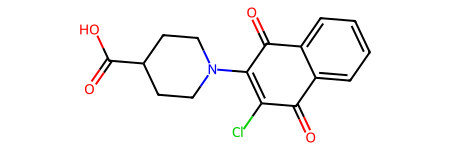

In [15]:
df['Mol'][11]

In [11]:
from rdkit.Chem import Descriptors
from rdkit.Chem.Descriptors import rdMolDescriptors



In [12]:
df.isna().sum()

smiles      0
name        0
Mol       387
dtype: int64

In [13]:
df.dropna(inplace=True)
df.reset_index(inplace=True, drop=True)

In [14]:
df

,smiles,name,Mol
0,CC(C)C1NC(=O)C(Cc2ccccc2)NC(=O)C(CC(O)=O)NC(=O...,CHEMBL3357753,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
1,Cc1cc(cc2[nH]c(nc12)C1=C(NCC(O)c2cccc(Cl)c2)C=...,CHEMBL520419,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
2,O=C(NN1CCN(CCc2c[nH]c3ccccc23)CC1)c1ccc(cc1)N(...,CHEMBL3273067,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
3,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
4,COc1ccccc1NC(=O)CSc1ccc(nn1)-c1ccc(cc1)-n1ccnc1,CHEMBL1442008,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...
...,...,...,...
499608,Clc1ccc2C(N3CCN(CC3)C(=O)C3CCNCC3)c3ncccc3CCc2c1,CHEMBL352634,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
499609,Cc1nc(sc1C(Cc1ccc(F)cc1F)Sc1ccc(OCC(O)=O)c(C)c...,CHEMBL2035060,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
499610,COC(=O)C(CC(C)=O)CS(=O)(=O)C=C(O)C(=O)Nc1cccc(...,CHEMBL2004630,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...
499611,COc1cc(C=CC(=O)c2cc(O)ccc2O)ccc1O,CHEMBL3335598,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...


In [16]:
df['LogP'] = df['Mol'].apply(Descriptors.MolLogP)

In [17]:
df['HbondDonors'] = df['Mol'].apply(Descriptors.NumHDonors)

In [18]:
df['HbondAcceptors'] = df['Mol'].apply(Descriptors.NumHAcceptors)

In [19]:
df['MolWt'] = df['Mol'].apply(Descriptors.MolWt)

In [20]:
df.isna().sum()

smiles            0
name              0
Mol               0
LogP              0
HbondDonors       0
HbondAcceptors    0
MolWt             0
dtype: int64

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999236 entries, 0 to 999235
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   smiles          999236 non-null  object 
 1   name            999236 non-null  object 
 2   Mol             999236 non-null  object 
 3   LogP            999236 non-null  float64
 4   HbondDonors     999236 non-null  int64  
 5   HbondAcceptors  999236 non-null  int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 45.7+ MB


In [21]:
df_filtered = df[
    (df['MolWt'] <= 500) &
    #(df['MolWt'] >= 200) &
    (df['LogP'] <= 5) &
    (df['HbondDonors'] <= 5) &
    (df['HbondAcceptors'] <= 10)
].copy()


In [22]:
df_filtered.reset_index(inplace=True, drop=True)

In [23]:
df_filtered

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt
0,Cc1cc(cc2[nH]c(nc12)C1=C(NCC(O)c2cccc(Cl)c2)C=...,CHEMBL520419,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.98662,5,6,493.995
1,O=C(NN1CCN(CCc2c[nH]c3ccccc23)CC1)c1ccc(cc1)N(...,CHEMBL3273067,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.58120,2,5,393.447
2,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413
3,COc1ccccc1NC(=O)CSc1ccc(nn1)-c1ccc(cc1)-n1ccnc1,CHEMBL1442008,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,4.06870,1,7,417.494
4,ClC1=C2CCC(N2C(=O)C(Cl)=C1)C(=O)N1CCCC1,CHEMBL479235,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.26480,0,3,301.173
...,...,...,...,...,...,...,...
357615,OC1=CC(=O)c2sc(SCC(=O)Nc3ccc(Br)cc3)nc2N1,CHEMBL1886456,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.18350,3,6,412.290
357616,CC(C)OP(=S)(OC(C)C)SCCNS(=O)(=O)c1ccccc1,CHEMBL1895252,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.77260,1,6,397.524
357617,Clc1ccc2C(N3CCN(CC3)C(=O)C3CCNCC3)c3ncccc3CCc2c1,CHEMBL352634,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.06680,1,4,424.976
357618,COC(=O)C(CC(C)=O)CS(=O)(=O)C=C(O)C(=O)Nc1cccc(...,CHEMBL2004630,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.11580,2,9,414.392


<Axes: >

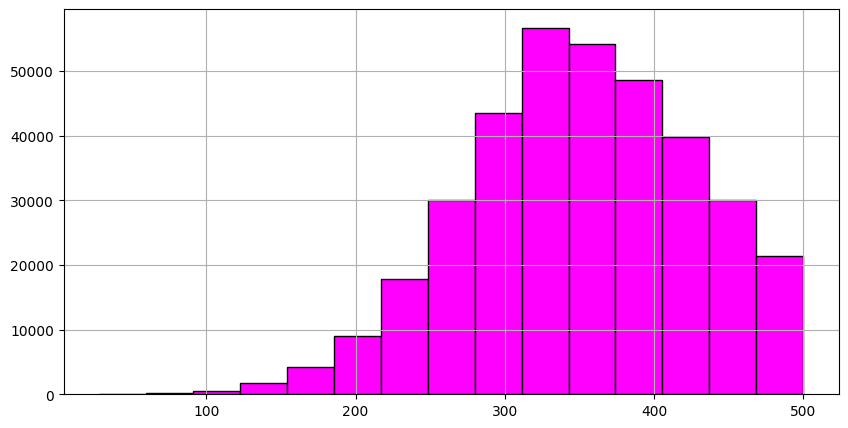

In [32]:
df_filtered['MolWt'].hist(bins= 15, figsize= (10, 5), edgecolor= 'black', color= 'magenta')

## ⚖️ QED (Quantitative Estimate of Drug-likeness)

QED is a metric that quantifies how "drug-like" a molecule is, based on a combination of several important physicochemical properties. It outputs a **single score between 0 and 1**, where **higher values indicate better drug-likeness** [(Bickerton et al., 2022)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3524573/#:~:text=To%20quantify%20compound%20quality%20we,one%20(all%20properties%20favourable).).

### 🧬 Properties Considered in QED
QED combines the following molecular features:

- Molecular weight (MW)
- LogP (lipophilicity)
- Hydrogen bond donors (HBD)
- Hydrogen bond acceptors (HBA)
- Rotatable bonds
- Aromatic ring count
- Structural alerts
- Topological polar surface area (TPSA)

### QED values can range between zero (all properties unfavourable) and one (all properties favourable).

### 📊 QED Score Range and Interpretation

| QED Score | Interpretation             |
|-----------|----------------------------|
| 0.9 – 1.0 | **Highly drug-like**       |
| 0.7 – 0.9 | **Moderately drug-like**   |
| 0.4 – 0.7 | **Potentially drug-like**  |
| < 0.4     | **Poor drug-likeness**     |

Most marketed oral drugs tend to have QED scores **above 0.67**, but this is not a strict cutoff.

> 📌 QED is especially useful for ranking and prioritizing compounds during virtual screening campaigns, as it provides a better view of drug-likeness rather than binary filtering.


In [33]:
df_filtered

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt
0,Cc1cc(cc2[nH]c(nc12)C1=C(NCC(O)c2cccc(Cl)c2)C=...,CHEMBL520419,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.98662,5,6,493.995
1,O=C(NN1CCN(CCc2c[nH]c3ccccc23)CC1)c1ccc(cc1)N(...,CHEMBL3273067,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.58120,2,5,393.447
2,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413
3,COc1ccccc1NC(=O)CSc1ccc(nn1)-c1ccc(cc1)-n1ccnc1,CHEMBL1442008,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,4.06870,1,7,417.494
4,ClC1=C2CCC(N2C(=O)C(Cl)=C1)C(=O)N1CCCC1,CHEMBL479235,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.26480,0,3,301.173
...,...,...,...,...,...,...,...
357615,OC1=CC(=O)c2sc(SCC(=O)Nc3ccc(Br)cc3)nc2N1,CHEMBL1886456,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.18350,3,6,412.290
357616,CC(C)OP(=S)(OC(C)C)SCCNS(=O)(=O)c1ccccc1,CHEMBL1895252,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.77260,1,6,397.524
357617,Clc1ccc2C(N3CCN(CC3)C(=O)C3CCNCC3)c3ncccc3CCc2c1,CHEMBL352634,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.06680,1,4,424.976
357618,COC(=O)C(CC(C)=O)CS(=O)(=O)C=C(O)C(=O)Nc1cccc(...,CHEMBL2004630,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.11580,2,9,414.392


In [34]:
df_filtered['Qed'] = df_filtered['Mol'].apply(Descriptors.qed)

<Axes: >

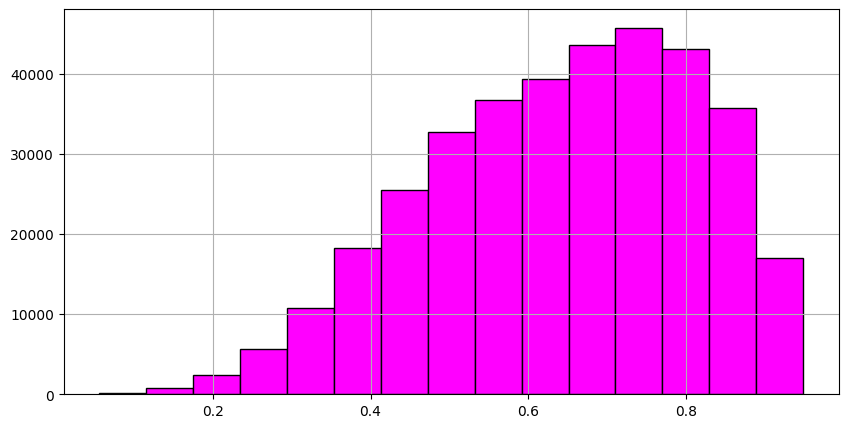

In [36]:
df_filtered['Qed'].hist(bins= 15, figsize=(10, 5),edgecolor= 'black', color='magenta')

In [39]:
df_filtered_qed =  df_filtered[df_filtered['Qed'] >= 0.6]

In [40]:
df_filtered_qed

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed
2,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340
4,ClC1=C2CCC(N2C(=O)C(Cl)=C1)C(=O)N1CCCC1,CHEMBL479235,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.26480,0,3,301.173,0.798285
8,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852
9,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090
10,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995
...,...,...,...,...,...,...,...,...
357608,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256
357611,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896
357612,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141
357613,CN(C)C(=O)N1CCN(CC1)C(c1cncnc1)c1ccc(Cl)cc1F,CHEMBL1863051,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.65770,0,4,377.851,0.824805


In [41]:
df_filtered_qed.isna().sum()

smiles            0
name              0
Mol               0
LogP              0
HbondDonors       0
HbondAcceptors    0
MolWt             0
Qed               0
dtype: int64

In [42]:
df_filtered_qed.reset_index(inplace=True, drop= True)

In [43]:
df_filtered_qed

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340
1,ClC1=C2CCC(N2C(=O)C(Cl)=C1)C(=O)N1CCCC1,CHEMBL479235,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.26480,0,3,301.173,0.798285
2,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852
3,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090
4,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995
...,...,...,...,...,...,...,...,...
218971,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256
218972,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896
218973,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141
218974,CN(C)C(=O)N1CCN(CC1)C(c1cncnc1)c1ccc(Cl)cc1F,CHEMBL1863051,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.65770,0,4,377.851,0.824805


## 🛠️ Synthetic Accessibility (SA) Score

The **Synthetic Accessibility (SA) Score** estimates how easy or difficult it would be to **chemically synthesize a compound** in the laboratory. It is a useful metric in drug discovery, especially after virtual screening, to prioritize molecules that are not only active but also practical to make.

### 🔬 How It Works
The SA score combines two key components:
1. **Fragment contributions** — How common or rare the molecular fragments are based on a large dataset of known synthetic compounds.
2. **Complexity penalties** — Structural features that increase synthetic difficulty, such as:
   - Large ring systems
   - Highly branched structures
   - Chiral centers
   - Unusual functional groups

### 📊 SA Score Range and Interpretation

| SA Score | Interpretation              |
|----------|-----------------------------|
| 1.0 – 3.0 | **Easy to synthesize**      |
| 3.1 – 5.0 | **Moderate difficulty**     |
| 5.1 – 10.0| **Difficult to synthesize** |

> ✅ Lower SA scores are more desirable when selecting compounds for further development, as they indicate a higher likelihood of successful synthesis.

### 🧪 Why It Matters
Even the most promising compound in terms of activity and drug-likeness may not be useful if it can't be synthesized efficiently. SA score helps avoid such dead ends early in the pipeline.


In [44]:
from rdkit.Contrib.SA_Score import sascorer

In [45]:
df_filtered_qed['sascore'] = df_filtered_qed['Mol'].apply(sascorer.calculateScore)

C:\Users\HomePC\AppData\Local\Temp\ipykernel_14380\3599187673.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_qed['sascore'] = df_filtered_qed['Mol'].apply(sascorer.calculateScore)


In [46]:
df_filtered_qed

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,ClC1=C2CCC(N2C(=O)C(Cl)=C1)C(=O)N1CCCC1,CHEMBL479235,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.26480,0,3,301.173,0.798285,3.068495
2,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
3,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
4,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
...,...,...,...,...,...,...,...,...,...
218971,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256,2.092328
218972,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
218973,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212
218974,CN(C)C(=O)N1CCN(CC1)C(c1cncnc1)c1ccc(Cl)cc1F,CHEMBL1863051,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.65770,0,4,377.851,0.824805,2.971823


<Axes: >

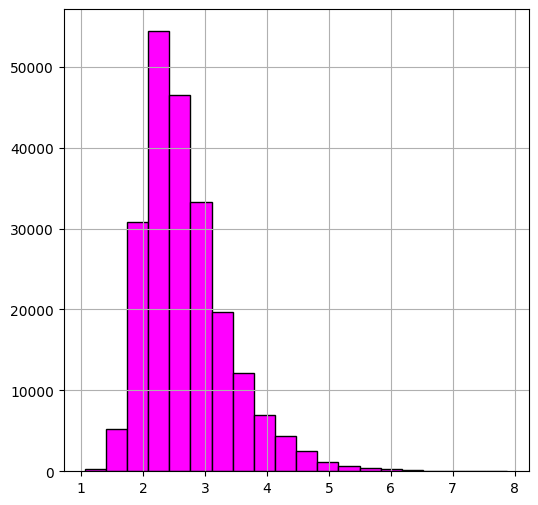

In [49]:
df_filtered_qed['sascore'].hist(bins=20, figsize=(6,6), edgecolor='black', color= 'magenta')

In [54]:
df_filtered_sascore = df_filtered_qed[df_filtered_qed['sascore'] <= 3.0]

In [55]:
df_filtered_sascore

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
2,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
3,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
4,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
5,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
218969,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
218971,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256,2.092328
218972,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
218973,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [57]:
df_filtered_sascore.isna().sum()

smiles            0
name              0
Mol               0
LogP              0
HbondDonors       0
HbondAcceptors    0
MolWt             0
Qed               0
sascore           0
dtype: int64

In [58]:
df_filtered_sascore.reset_index(inplace= True, drop= True)

In [59]:
df_filtered_sascore

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162026,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256,2.092328
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


## 🚫 PAINS (Pan Assay Interference Compounds)

**PAINS** are **Pan Assay Interference Compounds**—molecules that tend to give **false positive results** in biological assays. These compounds interfere with multiple assay types, not through specific biological activity, but through non-specific or reactive mechanisms.

### ⚠️ Why PAINS Are Problematic

- They may appear as "hits" in virtual screening or high-throughput screening campaigns.
- They often interfere with assay readouts due to:
  - Redox cycling
  - Covalent modification of proteins
  - Aggregation
  - Fluorescence interference

Because of this, they can **mislead drug discovery efforts** by diverting time and resources toward compounds with no true pharmacological potential.

### 🔬 How Are PAINS Identified?

PAINS filters use a set of predefined **substructure patterns** (SMARTS) to flag known problematic motifs. These filters were originally developed by Baell and Holloway (2010) after analyzing common assay artifacts.

### 🧪 In Practice

Before advancing any compound, it's good practice to **screen for PAINS** using computational filters (e.g., using RDKit or other cheminformatics tools) and **remove or deprioritize** flagged molecules.

> ✅ Removing PAINS helps improve the quality and reliability of your virtual screening pipeline.



In [60]:
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem.FilterCatalog import *
from rdkit.Chem import Descriptors, Draw, PandasTools

<frozen importlib._bootstrap>:488: RuntimeWarning: to-Python converter for class boost::shared_ptr<class RDKit::FilterHierarchyMatcher> already registered; second conversion method ignored.


In [61]:
df_filtered_sascore

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162026,Cc1nn(c(Oc2ccc(F)cc2)c1C=O)-c1ccccc1,CHEMBL2206580,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,3.92462,0,4,296.301,0.685256,2.092328
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [62]:
#filter by pains
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

In [63]:
substructures = pd.read_csv("pains_list.csv", sep="\s+")  
substructures["rdkit_molecule"] = substructures.smarts.apply(Chem.MolFromSmarts)
print("Number of unwanted substructures in collection:", len(substructures))

Number of unwanted substructures in collection: 104


<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\HomePC\AppData\Local\Temp\ipykernel_14380\2362051811.py:1: SyntaxWarning: invalid escape sequence '\s'
  substructures = pd.read_csv("pains_list.csv", sep="\s+")


In [64]:
substructures


,name,smarts,rdkit_molecule
0,>2EsterGroups,"C(=O)O[C,H1].C(=O)O[C,H1].C(=O)O[C,H1]",<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
1,2-haloPyridine,"n1c([F,Cl,Br,I])cccc1",<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
2,acidHalide,"C(=O)[Cl,Br,I,F]",<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
3,acyclic-C=C-O,C=[C!r]O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
4,acylCyanide,N#CC(=O),<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
...,...,...,...
99,thiol,[SH],<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
100,Three-membered-heterocycle,"*1[O,S,N]*1",<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
101,triflate,OS(=O)(=O)C(F)(F)F,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...
102,triphenyl-methylsilyl,"[SiR0,CR0](c1ccccc1)(c2ccccc2)(c3ccccc3)",<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...


In [65]:
from tqdm import tqdm

# search for unwanted substructure
matches = []
clean = []
for index, row in tqdm(df_filtered_sascore.iterrows(), total=df_filtered_sascore.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    match = False
    for _, substructure in substructures.iterrows():
        if molecule.HasSubstructMatch(substructure.rdkit_molecule):
            matches.append(
                {
                    "smiles": row.smiles,
                    "rdkit_molecule": molecule,
                    "substructure": substructure.rdkit_molecule,
                    "substructure_name": substructure["name"],
                }
            )
            match = True
    if not match:
        clean.append(index)

matches = pd.DataFrame(matches)
df_clean = df_filtered_sascore.loc[clean]




100%|██████████| 162030/162030 [48:18<00:00, 55.90it/s]  


In [66]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162024,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


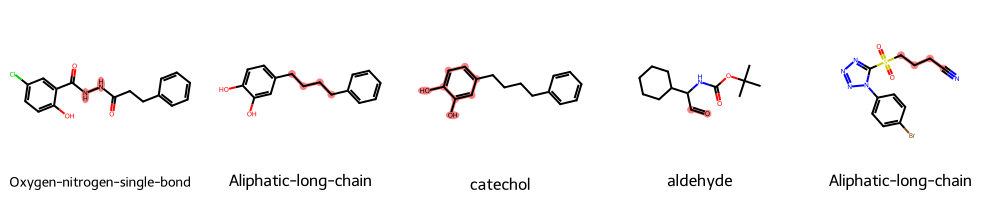

In [67]:
to_highlight = [
    row.rdkit_molecule.GetSubstructMatch(row.substructure) for _, row in matches.head(5).iterrows()
]
Chem.Draw.MolsToGridImage(
    list(matches.head(5).rdkit_molecule), molsPerRow=5,
    highlightAtomLists=to_highlight,
    legends=list(matches.head(5).substructure_name),
)



In [69]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162024,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [70]:
matches

,smiles,rdkit_molecule,substructure,substructure_name
0,Oc1ccc(Cl)cc1C(=O)NNC(=O)CCc1ccccc1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Oxygen-nitrogen-single-bond
1,Oc1ccc(CCCCc2ccccc2)cc1O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
2,Oc1ccc(CCCCc2ccccc2)cc1O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,catechol
3,CC(C)(C)OC(=O)NC(C=O)C1CCCCC1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,aldehyde
4,Brc1ccc(cc1)-n1nnnc1S(=O)(=O)CCCC#N,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
...,...,...,...,...
49500,COCCNC(=O)c1cnn2c(cc(nc12)-c1ccccc1)C(F)F,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
49501,CCC(C(O)=O)=C(CC)C(O)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor
49502,OC(=O)CC(=O)Nc1ccc(cc1)-c1nc2cccnc2[nH]1,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,betaketo/anhydride
49503,CCOc1ccc(cc1NC(=O)C=CC(O)=O)C(C)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor


c:\Users\HomePC\.conda\envs\ADVANCED\Lib\site-packages\rdkit\Chem\Draw\IPythonConsole.py:343: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


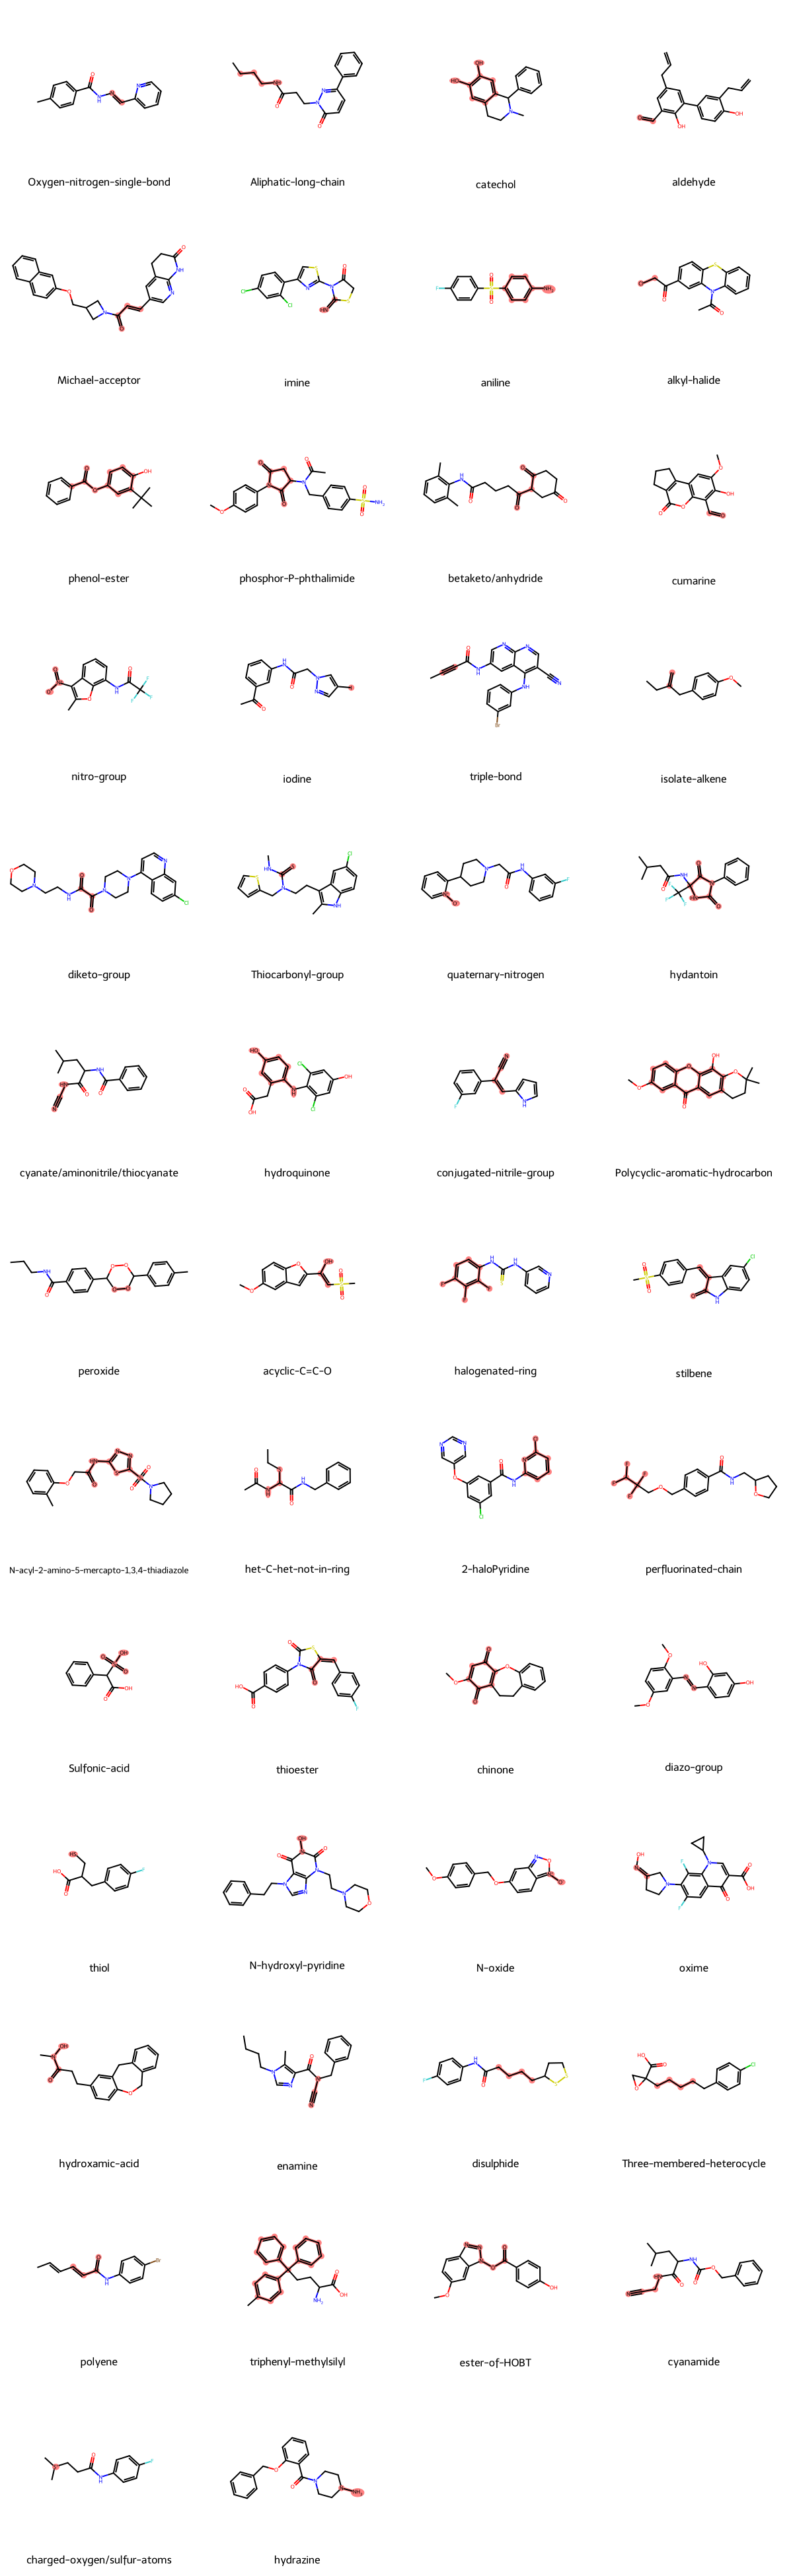

In [71]:

from rdkit.Chem import Draw
from collections import defaultdict
import random

pains_groups = defaultdict(list)

for idx, row in matches.iterrows():
    substructure_name = row['substructure_name']
    smiles = row['smiles']
    pains_groups[substructure_name].append(smiles)

# Step 2: Randomly select one molecule from each PAINS substructure group
selected_smiles = {group: random.choice(smiles_list) for group, smiles_list in pains_groups.items()}

# Step 3: Prepare molecules and highlight PAINS substructures
mols = []
highlight_atoms = []
legends = []

# Iterate through each selected molecule for a PAINS substructure
for pains_group, smiles in selected_smiles.items():
    mol = Chem.MolFromSmiles(smiles)
    mols.append(mol)
    
    # Get substructure match for PAINS
    substructure = matches[matches['smiles'] == smiles]['substructure'].values[0]
    match = mol.GetSubstructMatch(substructure)
    
    # Highlight the atoms in the substructure match
    if match:
        highlight_atoms.append(list(match))
    else:
        highlight_atoms.append([])  # If no match found, append empty list
    
    legends.append(f'{pains_group}')  # Add the group name to the legend

# Step 4: Draw molecules with highlighted PAINS substructures
img = Draw.MolsToGridImage(
    mols, 
    molsPerRow=4,  # 4 molecules per row
    subImgSize=(300, 300),  # Size of each subimage
    highlightAtomLists=highlight_atoms,  # Highlight PAINS substructures
    legends=legends  # Labels for the PAINS groups
)

# Step 5: Display the image
img

In [72]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162024,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [73]:
matches

,smiles,rdkit_molecule,substructure,substructure_name
0,Oc1ccc(Cl)cc1C(=O)NNC(=O)CCc1ccccc1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Oxygen-nitrogen-single-bond
1,Oc1ccc(CCCCc2ccccc2)cc1O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
2,Oc1ccc(CCCCc2ccccc2)cc1O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,catechol
3,CC(C)(C)OC(=O)NC(C=O)C1CCCCC1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,aldehyde
4,Brc1ccc(cc1)-n1nnnc1S(=O)(=O)CCCC#N,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
...,...,...,...,...
49500,COCCNC(=O)c1cnn2c(cc(nc12)-c1ccccc1)C(F)F,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
49501,CCC(C(O)=O)=C(CC)C(O)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor
49502,OC(=O)CC(=O)Nc1ccc(cc1)-c1nc2cccnc2[nH]1,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,betaketo/anhydride
49503,CCOc1ccc(cc1NC(=O)C=CC(O)=O)C(C)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor


#### You will notice the number of compounds in the `Matches` and `df_clean` dataframes do not sum up to our starting `df` number?
# WHY

In [74]:
matches.drop_duplicates(subset='smiles', inplace=True)

In [75]:
matches

,smiles,rdkit_molecule,substructure,substructure_name
0,Oc1ccc(Cl)cc1C(=O)NNC(=O)CCc1ccccc1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Oxygen-nitrogen-single-bond
1,Oc1ccc(CCCCc2ccccc2)cc1O,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
3,CC(C)(C)OC(=O)NC(C=O)C1CCCCC1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,aldehyde
4,Brc1ccc(cc1)-n1nnnc1S(=O)(=O)CCCC#N,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
5,C(CCn1nnnc1-c1ccc(cc1)-c1ccccc1)CN1CCOCC1,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
...,...,...,...,...
49500,COCCNC(=O)c1cnn2c(cc(nc12)-c1ccccc1)C(F)F,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Aliphatic-long-chain
49501,CCC(C(O)=O)=C(CC)C(O)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor
49502,OC(=O)CC(=O)Nc1ccc(cc1)-c1nc2cccnc2[nH]1,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,betaketo/anhydride
49503,CCOc1ccc(cc1NC(=O)C=CC(O)=O)C(C)=O,<rdkit.Chem.rdchem.Mol object at 0x00000201186...,<rdkit.Chem.rdchem.Mol object at 0x00000200F7C...,Michael-acceptor


In [76]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
162024,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
162025,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
162027,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
162028,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [77]:
df_clean.reset_index(inplace= True, drop= True)

In [78]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
120771,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
120772,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
120773,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
120774,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


## 🤝 Tanimoto Similarity

**Tanimoto Similarity** is a widely used metric in cheminformatics to compare the **structural similarity** between two molecules, typically using their **molecular fingerprints** (such as ECFP).

### 🧪 What It Measures

Tanimoto similarity quantifies how many structural features two molecules share:

$$
\text{Tanimoto Similarity} = \frac{c}{a + b - c}
$$

Where:  
- \( a \): Number of bits set to 1 in fingerprint A  
- \( b \): Number of bits set to 1 in fingerprint B  
- \( c \): Number of bits set to 1 in both A and B (the intersection)

### 📊 Similarity Score Range

| Tanimoto Score | Interpretation         |
|----------------|------------------------|
| 1.0            | Identical structures    |
| 0.7 – 0.99     | Highly similar          |
| 0.4 – 0.7      | Moderately similar      |
| < 0.4          | Weak or no similarity   |

### 🔍 Why It’s Useful

Tanimoto similarity is commonly used for:
- **Similarity-based virtual screening**
- Identifying analogs of known active compounds
- **Clustering** compounds by structure

> ✅ Molecules with a Tanimoto score above **0.7** to a known active are often prioritized in drug discovery.


In [79]:
df_clean

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.99750,1,4,306.413,0.807340,2.240281
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.14400,1,3,307.397,0.942852,2.866667
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.31260,1,4,319.744,0.905090,2.260376
3,CCN1C(CCC1=O)C(=O)NCc1ccc(Cl)cc1C,CHEMBL2218207,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.27552,1,2,294.782,0.925995,2.644327
4,Nc1nnc(SCC(=O)c2ccc3OCC(=O)Nc3c2)s1,CHEMBL1576494,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,1.42620,2,8,322.371,0.647292,2.519234
...,...,...,...,...,...,...,...,...,...
120771,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.91110,1,8,414.487,0.686286,2.541014
120772,CC1CCN(CC1)S(=O)(=O)c1ccc2N(C)C=C(C(=O)NCc3ccc...,CHEMBL1461306,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.95060,1,6,459.593,0.635410,2.426637
120773,OC(CN1N=Cc2ncccc2C1=O)c1cccc(Cl)c1,CHEMBL3462964,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.17850,1,5,301.733,0.804896,2.664657
120774,CN(C)c1ccc(cc1)C1=C(O)C(=O)c2c(O)cc(O)cc2O1,CHEMBL3335732,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,2.64280,3,6,313.309,0.673141,2.409212


In [88]:
from rdkit.Chem import AllChem
from rdkit import Chem, DataStructs
tqdm.pandas()

df_clean['Fingerprint'] = df_clean['Mol'].apply(lambda mol: AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=1024))


ref_smiles = 'C1=CC=C2C(=C1)C=CC=N2'  

ref_mol = Chem.MolFromSmiles(ref_smiles)
ref_fp = AllChem.GetMorganFingerprintAsBitVect(ref_mol, radius=2, nBits=1024)


df_clean['Tanimoto'] = df_clean['Fingerprint'].progress_apply(lambda fp: DataStructs.TanimotoSimilarity(ref_fp, fp))


df_screened = df_clean[df_clean['Tanimoto'] >= 0.1].copy()

df_screened

[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerator
[21:13:21] DEPRECATION WARNING: please use MorganGenerat

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore,Fingerprint,Tanimoto
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.9975,1,4,306.413,0.807340,2.240281,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.117647
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.1440,1,3,307.397,0.942852,2.866667,"[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, ...",0.125000
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.3126,1,4,319.744,0.905090,2.260376,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.108696
5,Fc1ccc(CNC(=O)c2ccccc2OCc2ccccc2)cc1,CHEMBL1365889,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,4.3347,1,2,335.378,0.727814,1.562928,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.125000
6,OCCNc1nccc2[nH]cnc12,CHEMBL284488,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,0.3621,3,4,178.195,0.634154,2.615313,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.142857
...,...,...,...,...,...,...,...,...,...,...,...
120764,CN1N=C(SC1=Nc1ccccc1)c1ccc(Cl)cc1,CHEMBL184806,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,4.0344,0,4,301.802,0.702519,2.215113,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.130435
120765,OC(=O)CCNC1=Nc2ccccc2CC1,CHEMBL1600120,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.7271,2,3,218.256,0.811712,2.473803,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.136364
120770,CCOC(=O)c1ccc(CSc2nc[nH]n2)o1,CHEMBL1492109,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.8667,1,6,253.283,0.646765,2.987559,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.115385
120771,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.9111,1,8,414.487,0.686286,2.541014,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",0.125000


In [89]:
df_screened.reset_index(inplace=True, drop=True)

In [90]:
df_screened

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore,Fingerprint,Tanimoto
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.9975,1,4,306.413,0.807340,2.240281,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.117647
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.1440,1,3,307.397,0.942852,2.866667,"[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, ...",0.125000
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.3126,1,4,319.744,0.905090,2.260376,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.108696
3,Fc1ccc(CNC(=O)c2ccccc2OCc2ccccc2)cc1,CHEMBL1365889,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,4.3347,1,2,335.378,0.727814,1.562928,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.125000
4,OCCNc1nccc2[nH]cnc12,CHEMBL284488,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,0.3621,3,4,178.195,0.634154,2.615313,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.142857
...,...,...,...,...,...,...,...,...,...,...,...
60595,CN1N=C(SC1=Nc1ccccc1)c1ccc(Cl)cc1,CHEMBL184806,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,4.0344,0,4,301.802,0.702519,2.215113,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.130435
60596,OC(=O)CCNC1=Nc2ccccc2CC1,CHEMBL1600120,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.7271,2,3,218.256,0.811712,2.473803,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.136364
60597,CCOC(=O)c1ccc(CSc2nc[nH]n2)o1,CHEMBL1492109,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.8667,1,6,253.283,0.646765,2.987559,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.115385
60598,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.9111,1,8,414.487,0.686286,2.541014,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",0.125000


In [91]:
df_screened[df_screened['Tanimoto'] >= 0.3].shape

(212, 11)

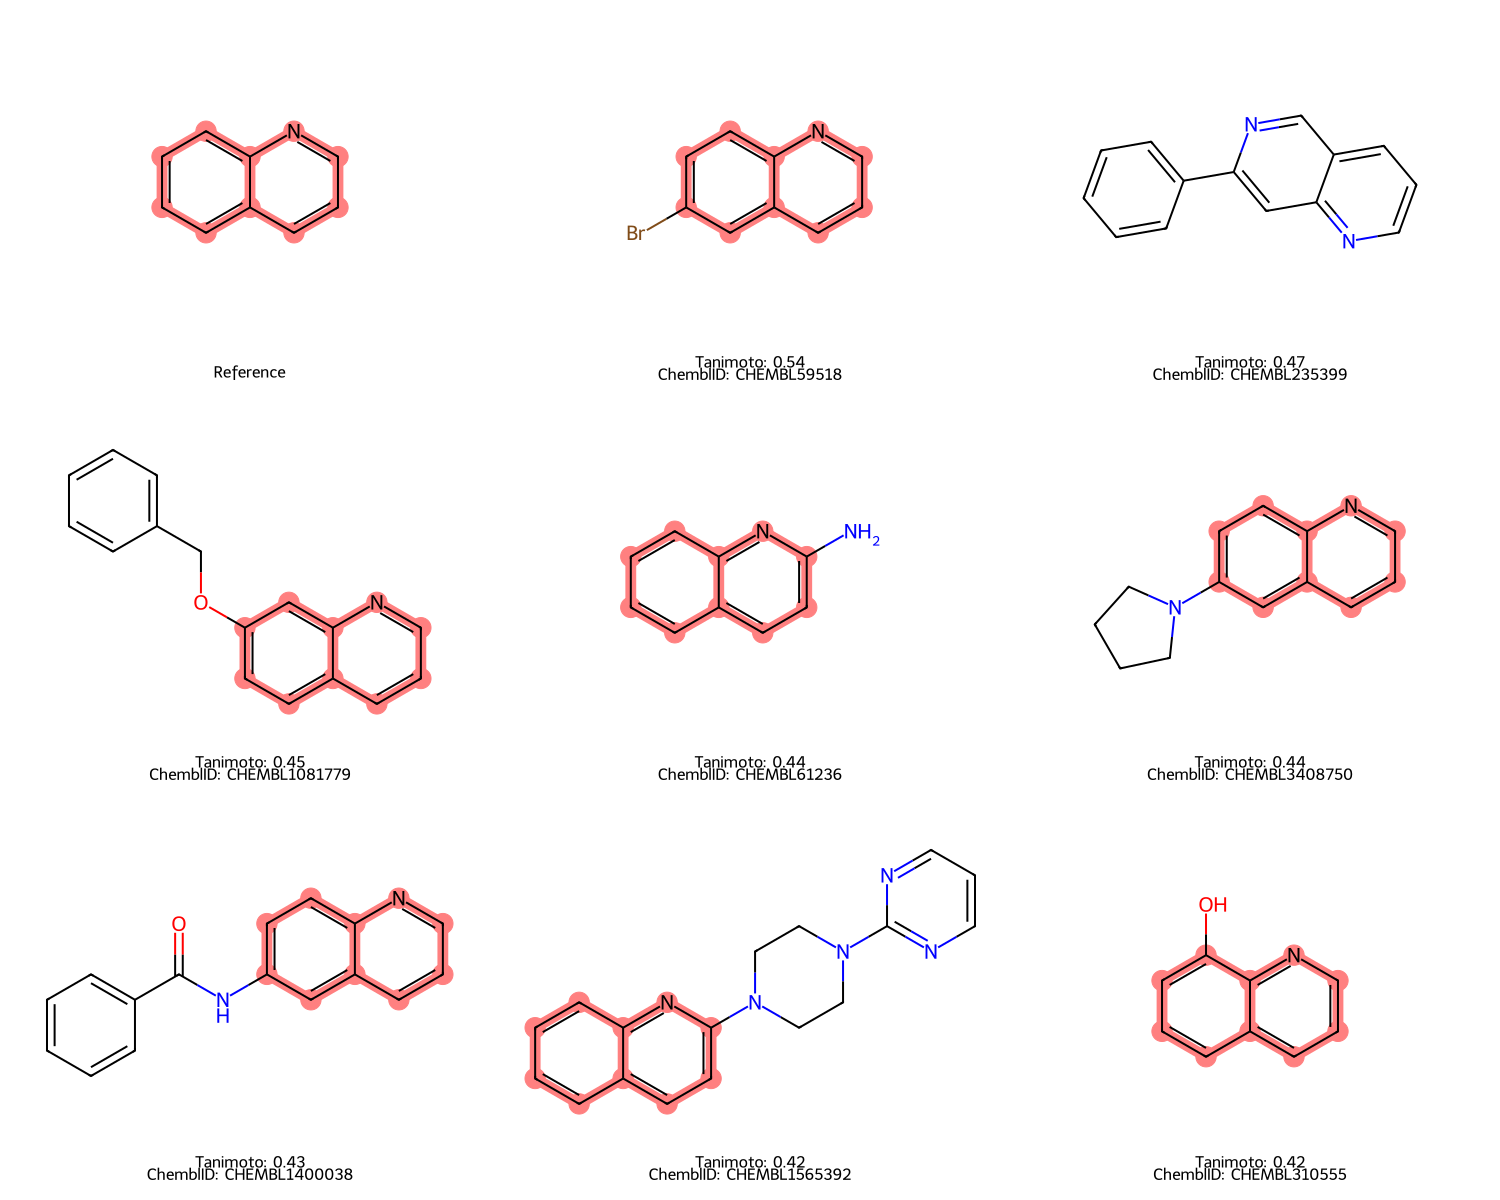

In [95]:
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import rdMolDraw2D

# Filter and get top 5 by Tanimoto similarity
top5 = df_screened.sort_values(by='Tanimoto', ascending=False).head(8)

# Convert SMILES to Mol objects (if needed)
top5_mols = [mol for mol in top5['Mol'] if mol is not None]

# Reference molecule from SMILES
ref_mol = Chem.MolFromSmiles(ref_smiles)
AllChem.Compute2DCoords(ref_mol)

# Generate 2D coordinates and align to reference
for mol in top5_mols:
    AllChem.Compute2DCoords(mol)
    try:
        AllChem.GenerateDepictionMatching2DStructure(mol, ref_mol)
    except ValueError:
        # Fallback: just use standard 2D coords
        pass

# Combine reference with top 5
mols_to_draw = [ref_mol] + top5_mols
legends = ['Reference'] + [f"Tanimoto: {sim:.2f}\nChemblID: {name}" 
                           for sim, name in zip(top5['Tanimoto'], top5['name'])]

# Highlight atoms (safely handle missing substructure matches)
highlight_atom_lists = []
for mol in mols_to_draw:
    if mol.HasSubstructMatch(ref_mol):
        match = mol.GetSubstructMatch(ref_mol)
    else:
        match = ()
    highlight_atom_lists.append(match)

# Draw grid image
img = Draw.MolsToGridImage(
    mols_to_draw,
    molsPerRow=3,
    subImgSize=(500, 400),
    legends=legends,
    highlightAtomLists=highlight_atom_lists
)

img


In [96]:
df_screened

,smiles,name,Mol,LogP,HbondDonors,HbondAcceptors,MolWt,Qed,sascore,Fingerprint,Tanimoto
0,CCc1nn(-c2ccccc2)c2cc(ccc12)N1CCNCC1,CHEMBL1809177,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.9975,1,4,306.413,0.807340,2.240281,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.117647
1,CCN(CC)C1N=C(c2ccccc2)c2ccccc2NC1=O,CHEMBL436769,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,3.1440,1,3,307.397,0.942852,2.866667,"[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, ...",0.125000
2,OC(=O)C1CCN(CC1)C1=C(Cl)C(=O)c2ccccc2C1=O,CHEMBL1599965,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,2.3126,1,4,319.744,0.905090,2.260376,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.108696
3,Fc1ccc(CNC(=O)c2ccccc2OCc2ccccc2)cc1,CHEMBL1365889,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,4.3347,1,2,335.378,0.727814,1.562928,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.125000
4,OCCNc1nccc2[nH]cnc12,CHEMBL284488,<rdkit.Chem.rdchem.Mol object at 0x000001FE7AA...,0.3621,3,4,178.195,0.634154,2.615313,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.142857
...,...,...,...,...,...,...,...,...,...,...,...
60595,CN1N=C(SC1=Nc1ccccc1)c1ccc(Cl)cc1,CHEMBL184806,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,4.0344,0,4,301.802,0.702519,2.215113,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.130435
60596,OC(=O)CCNC1=Nc2ccccc2CC1,CHEMBL1600120,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.7271,2,3,218.256,0.811712,2.473803,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.136364
60597,CCOC(=O)c1ccc(CSc2nc[nH]n2)o1,CHEMBL1492109,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.8667,1,6,253.283,0.646765,2.987559,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.115385
60598,COc1ccccc1N1CCN(CC1)C(=O)CCN1C(=O)N=C2C=CSC2=C1O,CHEMBL1407041,<rdkit.Chem.rdchem.Mol object at 0x00000200D56...,1.9111,1,8,414.487,0.686286,2.541014,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",0.125000


array([[<Axes: title={'center': 'LogP'}>,
        <Axes: title={'center': 'HbondDonors'}>,
        <Axes: title={'center': 'HbondAcceptors'}>],
       [<Axes: title={'center': 'MolWt'}>,
        <Axes: title={'center': 'Qed'}>,
        <Axes: title={'center': 'sascore'}>],
       [<Axes: title={'center': 'Tanimoto'}>, <Axes: >, <Axes: >]],
      dtype=object)

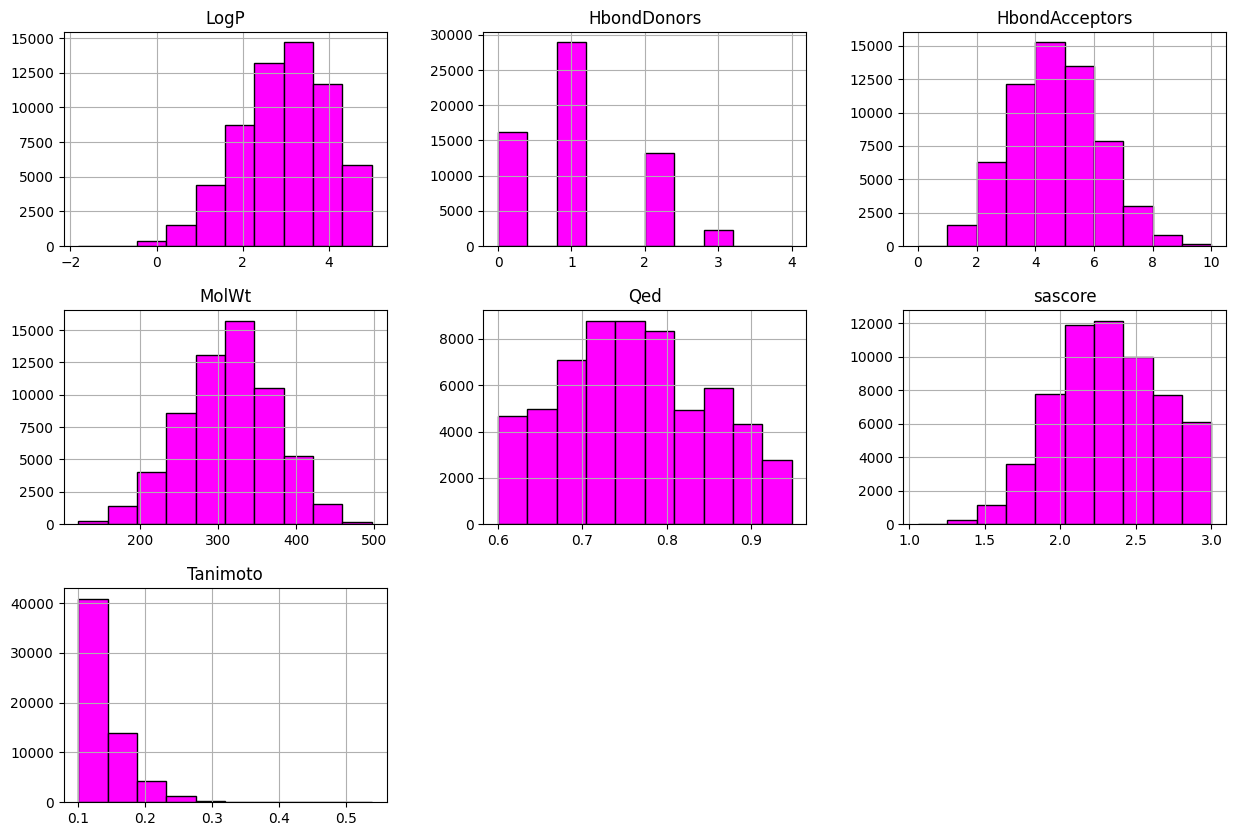

In [103]:
df_screened.hist(bins= 10, figsize= (15, 10), edgecolor= 'black', color= 'magenta')